## MATH3603 Deep Learning & Explainable AI ─ Assignment 1


<div class="logos"><img src="MATH3603_logo.jpg" width="125px" align="right"></div>

This assignment is designed to test your basic understanding of artificial neural networks. The task consists of two parts with practical questions for you to answer using Python: 
> **Part A.** Define and implement the basic elements of a neural network [**40 marks**]<br>
> **Part B.** Carry out image classification using a Multilayer Perceptron (MLP) [**60 marks**]

The maximum number of marks for each part is shown above, with a total of **100 marks** available. Partial marks for individual tasks are shown below in the section headings.

**This is a summative assessment contributing 30% to the final module grade.**

### Objectives 

Through this assignment you will:

> - Demonstrate understanding of the design and essential ingredients of a simple neural network.
> - Design and build your first deep neural network (DNN). 
> - Train a DNN model for image classification of natural scene data.  
> - Use various metrics to ascertain how your DNN model is performing. 


### Setup and resources 

> - You must work using the template notebook provided with the task. 
> - Please **do not remove anything in the template**. You are allowed to add new code cells.
> - You should implement this assignment using **Python** and **PyTorch**.

Having a GPU will speed up the training process. See the document "Computing Information Sheet" on Minerva about setting up a working environment and various ways to access a GPU.

#### Required packages

Please make sure that you have the following basic packages installed before you begin:
> - [numpy](https://www.numpy.org) is a package for scientific computing with Python
> - [h5py](https://www.h5py.org) is a package to interact with compactly stored datasets
> - [matplotlib](https://matplotlib.org) can be used for plotting graphs in Python
> - [PyTorch](https://pytorch.org/docs/stable/index.html) is a library widely used for building deep-learning frameworks

If needed, you can install these and other packages using [pip](https://pypi.org/project/opencv-python/) or [conda](https://anaconda.org/conda-forge/opencv).

Importing some other packages may be required; hints are provided for you in the template below.


### Submission

#### Due date
The assignment is released on Minerva on Friday 9th October 2026 and is due for submission via Gradescope **by 09:00 on Monday 2nd November 2026**. 

If you submit your work past the deadline, penalties will be applied: for every period of 24 hours or part thereof that your assessment is overdue, you will lose 5% of the total marks available for that assessment component. This includes weekends, Bank Holidays and University closed days. 

If you are unable to submit your work on time, please consider applying for an extension or exemption due to mitigating circumstances.

#### What to submit

Please submit a single `*.zip` file through **Minerva Gradebook Submission**, comprising the following files:

> 1. Your completed Jupyter notebook as `*.ipynb` file.
> 2. The `*.html` version of your notebook (saved using **File > Save and Export Notebook As > HTML**).
> 3. Academic integrity statement (signed and dated) including the Gen AI use disclosure.

#### Further guidance

> - In each section, put the relevant code containing your solution.
> - When defining a function, please add a description of the arguments, along with their dimensions (shapes).
> - Please annotate your code as appropriate to make it more readable for humans and to explain your chain of thought.
> - You may re-use functions you defined previously, but any new code must be in the relevant section.
> - Feel free to add as many code cells as you need under each section.
> - Before submission, check that all Python cells have been run.
> - Make sure that all outputs (including all graphs you would like to be marked) are displayed in the `*.html` file that you will submit for marking.

#### Your details

Your full name:

Richard Ubege

Your student username (e.g. `mm24jb`): 

cm23ru

## Part A: Design and Ingredients of a Neural Network [40 marks]

### Tasks

> **A1.** Define the sigmoid activation function and plot its graph [10 marks] <br>
> **A2.** Implement forward pass including weights [10 marks] <br>
> **A3.** Define and evaluate the cost value [10 marks] <br>
> **A4.** Implement backward pass and update the weights [10 marks]

To answer these questions, please provide the required Python code in the code cells below and run it on a specific DNN example shown below:

<div class="figure"><img src="Assessment_1_figure.jpg" width="620px" align="center"></div>

<br>

This figure represents a two-layer neural network (with sigmoid activation functions) for classification of 2D input vectors $\begin{bmatrix}x_1\\x_2\end{bmatrix}$ into 2 x 2 = 4 classes  labelled $\begin{bmatrix}0\\0\end{bmatrix}$, $\begin{bmatrix}1\\0\end{bmatrix}$, $\begin{bmatrix}0\\1\end{bmatrix}$, and $\begin{bmatrix}1\\1\end{bmatrix}$. The input values, as well as the associated weights and biases in each layer, are shown in the figure. The neurons in the output layer produce their scalar predictions independently, with the corresponding ground truth `0/1` shown on the right. 

<br>

**Notation:**
> $x$ -- training instance (input) <br>
> $y_{\text{true}}$ -- ground truth <br>
> $z$ -- affine transformation of $x$ <br>
> $w$ -- weight <br>
> $b$ -- bias <br>
> $a$ -- activation through sigmoid

##### Installing required Packages

In [96]:
%pip install numpy
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [97]:
import numpy as np 
#Useful package for working with vectors/matrices

### A1. Activation function [10 marks]

#### A1.1. Define the sigmoid activation function

The sigmoid sfunction is defined as:

$$\sigma(x)=\frac{1}{1+e^{-x}}$$

Its range is the interval $(0, 1)$ with large values mapping close to 1 and small (i.e increasingly negative) values mapping close to 0

In [98]:
# Your code here:
def sigmoid(x):
    '''
    x: 
        scalar or n-dimensional array, shape(n, )
    returns: 
        sigmoid(x) for all (or just one) elements
        in x
    '''
    return 1 / (1 + np.exp(-x))

    

#### A1.2. Print `sigmoid(-0.2) = <value>` with 4 decimal places

In [99]:
# Your code here:
print(f'sigmoid(-0.2) = {round(sigmoid(-0.2), 4)}')

sigmoid(-0.2) = 0.4502


#### A1.3. Plot the graph of `y = sigmoid(x)`

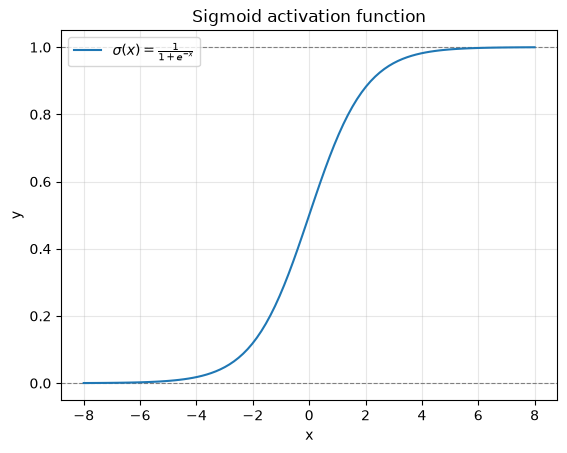

In [100]:
import matplotlib.pyplot as plt

xmin, xmax, n = -8, 8, 100

#Makes n evenly spaced points in the interval [xmin, xmax]
x = np.linspace(xmin, xmax, n)

#Compute sigmoid(x) for each element in x
y = sigmoid(x)

#Some 'prettying up' of the plot
plt.xlabel('x')
plt.ylabel('y')
plt.title('Sigmoid activation function')
plt.grid(alpha=0.3)

#Horizontal asymptotes
plt.axhline(0, color="grey", ls="--", lw=0.8)
plt.axhline(1, color="grey", ls="--", lw=0.8)


#Plotting
plt.plot(x, y, label=r"$\sigma(x)=\frac{1}{1+e^{-x}}$")
plt.legend(loc='upper left')
plt.show()


### A2. Forward propagation [10 marks]

#### A2.1. Define forward pass 

In [101]:
def forward_pass(W, b, X):
    """  
    Arguments:
    W -- Array of network weights, shape (p, n)
    b -- Array of network biases, shape (p, )
    X -- input vector, shape (n, )

    Return:
    Z -- array of affine outputs
    A -- array of sigmoid-transformed outputs
    """

# Forward propagation (affine transform)
#Initialise the arrays storing the outputs
    Z, A = [], []
    #Output from previous layer, start with inital input vector
    a_prev = X
    
# Activation
    for W_l, b_l in zip(W, b):
        z = np.matmul(W_l, a_prev) + b_l
        a = sigmoid(z)
        Z.append(z)
        A.append(a)
        
        #Reset a_prev to new value so loop can start for next layer
        a_prev = a

    return Z, A

#### A2.2. Find forward pass for the hidden layer

In [102]:
# Your code here:
X = np.array([0.1, 0.5])

W = np.array([
    [[0.1, 0.3],
     [0.2, 0.4]],

     [[0.5, 0.6],
      [0.7, 0.8]]
])

b = np.array([
    [0.25, 0.25],
    [0.35, 0.35]
])

Z, A = forward_pass(W, b, X)

#index n=0 is the forward pass for first hidden layer
#with indexes n=n+1 being forward passes for successive hidden 
#layers and index -1 (last index) being output. In this case,
#only one hidden layer

print(f'Z for hidden layer: {Z[0]}')
print(f'A for hidden layer: {A[0]}')

Z for hidden layer: [0.41 0.47]
A for hidden layer: [0.60108788 0.61538376]


In [103]:
# Optional: manual check

# print(W.T)

# print(W[0])

Z_11, Z_12 = np.matmul(W[0], X) + b[0]


print(Z_11)
print(Z_12)


print(sigmoid(Z_11), sigmoid(Z_12))

0.41000000000000003
0.47
0.6010878788483698 0.6153837563911821


#### A2.3. Find the prediction values from the output layer

In [104]:
# Your code here:
print(f'Output layer: {A[-1]}')
print(f'y1 = {A[-1][0]}')
print(f'y2 = {A[-1][1]}')



Output layer: [0.73492861 0.77955388]
y1 = 0.7349286127170142
y2 = 0.7795538841677558


Outputs from neurones can be thought of as probability that
(the network 'thinks') the correct label is 1

### A3. Cost value [10 marks]

#### A3.1. Define the cost using negative log-liklihood loss (binary cross entropy)

In [105]:
def cost(Y_out, Y_true):
    """
    Binary cross entropy (negative log-likelihood), averaged over the output neurons.
    
    Arguments:
    Y_out  -- predicted probabilities of label 1 (output of the sigmoid), shape (n,)
    Y_true -- ground-truth labels, each 0 or 1, shape (n,)

    Return:
    J -- scalar cost
    """
    
    # Your code here
    # probability the network gave to the true label: y_hat if y = 1, (1 - y_hat) if y = 0
    p_true = Y_true * Y_out + (1 - Y_true) * (1 - Y_out)
    return -np.mean(np.log(p_true))



#### A3.2. Find the cost over one iteration (forward pass)

In [106]:
# Your code here: 
output = A[-1]

print('Cost:')
cost1 = cost(output, np.array([0, 1]))
print(cost(output, np.array([0, 1])))



Cost:
0.7883947847977222


### A4. Backward propagation [10 marks]
This is the process of changing the DNN parameters (weights/biases) using the gradient descent algorithm (at a certain learning rate).

#### A4.1. Define backward pass

In [107]:
#Sigmoid function derivative can be nicely written in terms
#of the original function

def sigmoid_derivative(x):
    return sigmoid(x) * (1 - sigmoid(x))

def backward_pass(W, b, X, Z, A, Y_true):
    """
    Backward propagation (chain rule) for the network
    Computes gradients using the current weights.

    Arguments:
    W -- array of weight matrices, shape (p, n)
    b -- array of bias vectors, each (p,)
    X -- input vector, shape (n,)
    Z -- array of affine outputs from forward_pass
    A -- array of activations from forward_pass
    Y_true -- ground-truth labels

    Return:
    dW -- list of gradients dJ/dW[l], same shapes as W
    db -- list of gradients dJ/db[l], same shapes as b
    cost_value -- cost for this forward pass
    """
    N = len(Y_true)
    y_hat = A[-1]

    # ---- output layer ----
    dA2 = (-(Y_true / y_hat) + (1 - Y_true) / (1 - y_hat)) / N   # dJ/da^[2]            
    dZ2 = dA2 * sigmoid_derivative(Z[1])                         # dJ/dz^[2]           
    dW2 = np.outer(dZ2, A[0])                                    # dJ/dW^[2] = dz2 a1^T 
    db2 = dZ2                                                    # dJ/db^[2]            

    # ---- hidden layer (error sent back through the OLD output weights) ----
    dA1 = W[1].T @ dZ2                                           # dJ/da^[1]          
    dZ1 = dA1 * sigmoid_derivative(Z[0])                         # dJ/dz^[1]            
    dW1 = np.outer(dZ1, X)                                       # dJ/dW^[1] = dz1 x^T  
    db1 = dZ1                                                    # dJ/db^[1]            

    # Return gradients (of weights and biases seperately), and cost
    return [dW1, dW2], [db1, db2], cost(y_hat, Y_true)

#### A4.2. Implement backward pass and update the output layer

In [118]:
# Your code here


Y_true = np.array([0, 1])
learning_rate = 0.1  # eta (step size of gradient descent)

dW, db, J = backward_pass(W, b, X, Z, A, Y_true)
print(f"Cost before update: {J:.4f}\n")
print("dJ/dW^[2] =\n", dW[1])
print("dJ/db^[2] =", db[1])

# Work on copies so the original parameters stay available for comparison
W_new = [w.copy() for w in W]
b_new = [v.copy() for v in b]

# Gradient-descent update of the output layer
W_new[1] = W[1] - learning_rate * dW[1]
b_new[1] = b[1] - learning_rate * db[1]

print("\nUpdated W^[2] =\n", W_new[1])
print("Updated b^[2] =", b_new[1])



Cost before update: 0.7884

dJ/dW^[2] =
 [[ 0.22087834  0.22613157]
 [-0.06625374 -0.06782948]]
dJ/db^[2] = [ 0.36746431 -0.11022306]

Updated W^[2] =
 [[0.47791217 0.57738684]
 [0.70662537 0.80678295]]
Updated b^[2] = [0.31325357 0.36102231]


#### A4.4. Update the hidden layer

In [119]:
# Your code here:

print("dJ/dW^[1] =\n", dW[0])
print("dJ/db^[1] =", db[0])

# Gradient-descent update of the hidden layer
W_new[0] = W[0] - learning_rate * dW[0]
b_new[0] = b[0] - learning_rate * db[0]

print("\nUpdated W^[1] =\n", W_new[0])
print("Updated b^[1] =", b_new[0])

Z_new, A_new = forward_pass(W_new, b_new, X)

new_cost = cost(A_new[-1], Y_true)

print(new_cost)



dJ/dW^[1] =
 [[0.00255549 0.01277746]
 [0.00313137 0.01565683]]
dJ/db^[1] = [0.02555493 0.03131367]

Updated W^[1] =
 [[0.09974445 0.29872225]
 [0.19968686 0.39843432]]
Updated b^[1] = [0.24744451 0.24686863]
0.7628154940128473


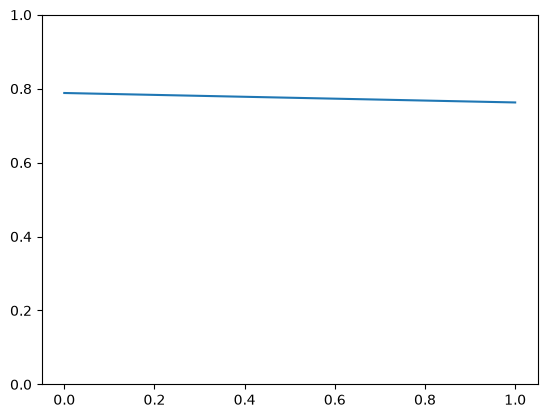

In [120]:
plt.ylim((0,1))
plt.plot([0,1 ], [cost1, new_cost])


## Part B: Image Classification Using a Multilayer Perceptron (MLP) [60 marks]

### Tasks

> **B1.** Image classification: overview and implementation [20 marks] <br>
> **B2.** Model training and evaluation [40 marks]
> 
### Dataset
This assignment will use a subset of images from the [Tiny ImageNet dataset](https://www.image-net.org/update-mar-11-2021.php). This subset contains 30 different categories and will be referred to as `TinyImageNet30`. The training set has 450 resized images (64 x 64 pixels) for each category (13,500 images in total). You can download the training and test sets from [Kaggle](https://www.kaggle.com/code/ml19hm3/image-classification)  or directly from here:

>[Please use your university email to access this link](https://leeds365-my.sharepoint.com/:f:/g/personal/stalvb_leeds_ac_uk/IgDHgPJUMZL4QYHZOAdC2hqQAflTaZ555YHas-g3Du8j5iQ?e=0UjxY5)

In [121]:
%pip install opencv-python
%pip install torch
%pip install cv2

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement cv2 (from versions: none)
ERROR: No matching distribution found for cv2


In [122]:
import cv2
import math

import numpy as np

import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.hub import load_state_dict_from_url

from PIL import Image
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'torchvision'

In [ ]:
# Check your version
print(torch.__version__)

One challenge of building a deep learning model is to choose an architecture that can learn the features in the dataset without being unnecessarily complex. The first part of the assignment involves building an MLP (type of DNN) and training it on `TinyImageNet30`. 

### B1. Image classification: overview and implementation [20 marks]

#### B1.1. PyTorch data classes

Write PyTorch classes `Dataset` to load the `TinyImage30` dataset and `DataLoaders` to create training and validation subsets.

In [ ]:
# Your code here:
image_size = 64


#### B1.2. Define the MLP `Model` class

Create a new model using a combination of:
- Input units
- Hidden units
- Output units
- Activation functions
- Loss function
- Optimiser

In [ ]:
# Your code here to define the MLP Model




### B2. Model training and evaluation [40 marks]

#### B2.1. Train your MLP model

Train your model on the `TinyImageNet30` dataset. Split the data into train and validation sets to determine when to stop training. Use seed at `0` for reproducibility and `test_ratio = 0.2` (validation data).

Display the graph of training and validation loss over epochs and accuracy over epochs to show how you determined the optimal number of training epochs. A top-*k* accuracy implementation is provided for you below.

> Show loss and accuracy graphs side by side (e.g., use the same graph to plot both training and validation results).


In [ ]:
# (HelperDL function) -- Define top-*k* accuracy
def topk_accuracy(output, target, topk=(1,)):
    """
    Computes Precision@k for the specified range of top images returned by the model.
    This evaluation metric measures the proportion of relevant results out of top k. 
    
    """
    
    maxk = max(topk)
    batch_size = target.size(0)
    _, pred = output.topk(maxk, 1, True, True)
    pred = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))

    res = []
    for k in topk:
        correct_k = correct[:k].view(-1).float().sum(0)
        res.append(correct_k.mul_(100.0 / batch_size))
    return res

In [ ]:
# Your code --> Running your MLP model class



In [ ]:
# Your graph



> Please comment on your model and the results you have obtained. This should include the number of parameters for your model.

#### B2.2. Generating confusion matrices and ROC curves

- Use your MLP architecture to generate two confusion matrices, one for the training set and another for the validation set.
- Remember to use the whole validation and training sets, and to include all your relevant code.
- Display the confusion matrices in a meaningful way which clearly indicates what percentage of the data is represented in each position.
- Display ROC curves for the two highest-performing and two lowest-performing classes, including the area under the curve (AUC) for each class. Comment on the results.

In [ ]:
# Your code here

In [ ]:
# Your code here

##### The end if this assignment.